# Analysis: Broadway Attendance and Theater District Taxi Demand, 2024

Statistical analysis and visualisation for the three weekly datasets built in `preprocessing_notebook_part_3.ipynb`. This notebook loads the saved CSVs directly and does not require a Spark session.

## Load the preprocessed weekly datasets

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

analysis_ready_dir = "../data/analysis_ready"

plot_data = pd.read_csv(f"{analysis_ready_dir}/theater_district_weekly.csv", parse_dates=["week_ending"])
control_plot_data = pd.read_csv(f"{analysis_ready_dir}/control_zone_weekly.csv", parse_dates=["week_ending"])
fhvhv_plot_data = pd.read_csv(f"{analysis_ready_dir}/fhvhv_theater_district_weekly.csv", parse_dates=["week_ending"])

control_zone_name = "Murray Hill"

plot_data.head()

,week_ending,weekly_trips,weekly_fares,weekly_tips,ID,gross,attendance,% Capacity,_c5
0,2024-01-07,74576,1195884.93,212435.73,58,29681396.0,219787.0,0.93,NaN
1,2024-01-14,77114,1154248.07,225651.86,57,27657991.0,218287.0,0.90,NaN
2,2024-01-21,74916,1147713.33,224299.45,56,23589174.0,204612.0,0.86,NaN
3,2024-01-28,77687,1182120.90,230067.62,55,24615726.0,217847.0,0.92,NaN
4,2024-02-04,75213,1156082.95,227796.55,54,23493675.0,213281.0,0.93,NaN


## Theater District: Yellow Taxi trips vs Broadway attendance

In [2]:
import matplotlib.pyplot as plt

plot_data["trips_scaled"] = (
    plot_data["weekly_trips"] / plot_data["weekly_trips"].max()
)

plot_data["attendance_scaled"] = (
    plot_data["attendance"] / plot_data["attendance"].max()
)

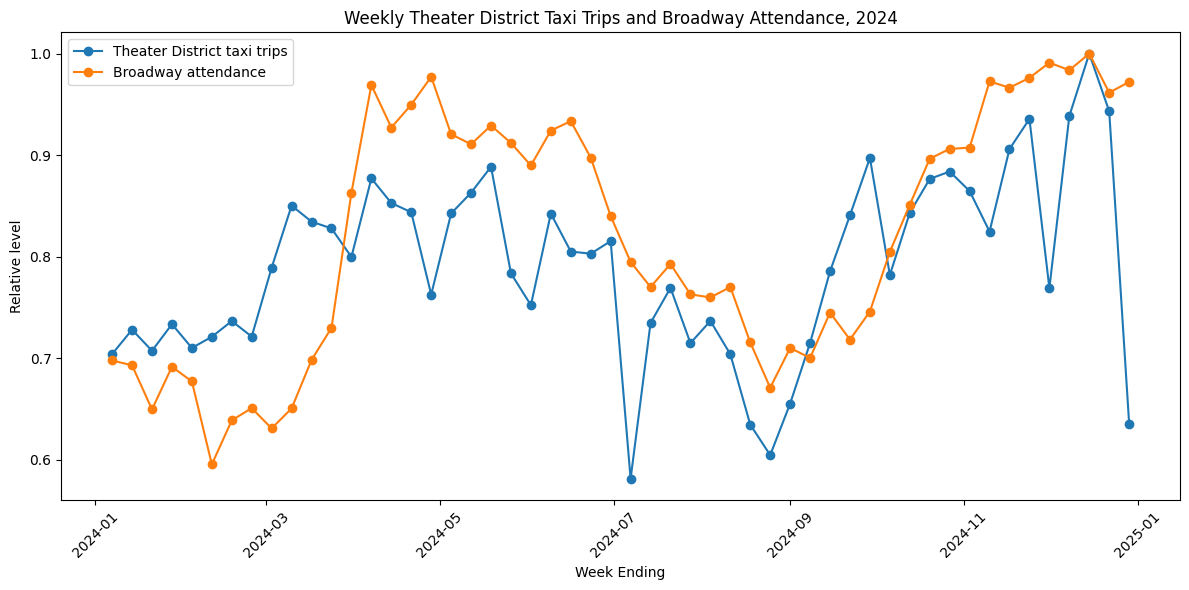

In [3]:
plt.figure(figsize=(12, 6))

plt.plot(
    plot_data["week_ending"],
    plot_data["trips_scaled"],
    marker="o",
    label="Theater District taxi trips"
)

plt.plot(
    plot_data["week_ending"],
    plot_data["attendance_scaled"],
    marker="o",
    label="Broadway attendance"
)

plt.xlabel("Week Ending")
plt.ylabel("Relative level")
plt.title("Weekly Theater District Taxi Trips and Broadway Attendance, 2024")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
plot_data["weekly_trips"].corr(plot_data["attendance"])

np.float64(0.5651796777438451)

**Statistical significance.** A raw correlation coefficient on its own doesn't say whether the relationship is likely real given only 52 weekly points — report both the Pearson coefficient (linear relationship) and its p-value, plus Spearman's (rank-based, less sensitive to a handful of extreme weeks like the December holiday peak).

In [5]:
from scipy import stats

pearson_r, pearson_p = stats.pearsonr(plot_data["weekly_trips"], plot_data["attendance"])
spearman_r, spearman_p = stats.spearmanr(plot_data["weekly_trips"], plot_data["attendance"])

print("Yellow Taxi (Theater District) vs Broadway attendance")
print(f"  Pearson  r = {pearson_r:.4f}  (p = {pearson_p:.4g})")
print(f"  Spearman r = {spearman_r:.4f}  (p = {spearman_p:.4g})")

Yellow Taxi (Theater District) vs Broadway attendance
  Pearson  r = 0.5652  (p = 1.27e-05)
  Spearman r = 0.5692  (p = 1.066e-05)


**De-trended check.** Both series likely share a December-holiday / seasonal pattern that has nothing to do with each other causally. Correlating *week-over-week changes* rather than raw levels removes a shared slow trend and gives a more honest read on whether the two series move together beyond that shared seasonality.

In [6]:
plot_data_sorted = plot_data.sort_values("week_ending").reset_index(drop=True)
trips_pct_change = plot_data_sorted["weekly_trips"].pct_change()
attendance_pct_change = plot_data_sorted["attendance"].pct_change()

detrended_r, detrended_p = stats.pearsonr(
    trips_pct_change.dropna(), attendance_pct_change.dropna()
)
print(f"De-trended (week-over-week change) correlation: "
      f"r = {detrended_r:.4f}  (p = {detrended_p:.4g})")

De-trended (week-over-week change) correlation: r = 0.0858  (p = 0.5496)


**Control zone comparison.** If a comparable non-theater Manhattan zone shows a similarly strong correlation with Broadway attendance, the Theater District result is likely picking up general Midtown/holiday seasonality rather than a theater-specific effect. If the control zone's correlation is much weaker, that's a stronger case for a real relationship.

In [7]:
control_pearson_r, control_pearson_p = stats.pearsonr(
    control_plot_data["weekly_trips"], control_plot_data["attendance"]
)

print(f"Control zone ({control_zone_name}) vs Broadway attendance")
print(f"  Pearson r = {control_pearson_r:.4f}  (p = {control_pearson_p:.4g})")

print("\nComparison:")
print(f"  Theater District r = {pearson_r:.4f}")
print(f"  Control zone r     = {control_pearson_r:.4f}")
print(f"  Difference          = {pearson_r - control_pearson_r:.4f}")

Control zone (Murray Hill) vs Broadway attendance
  Pearson r = 0.3770  (p = 0.005874)

Comparison:
  Theater District r = 0.5652
  Control zone r     = 0.3770
  Difference          = 0.1882


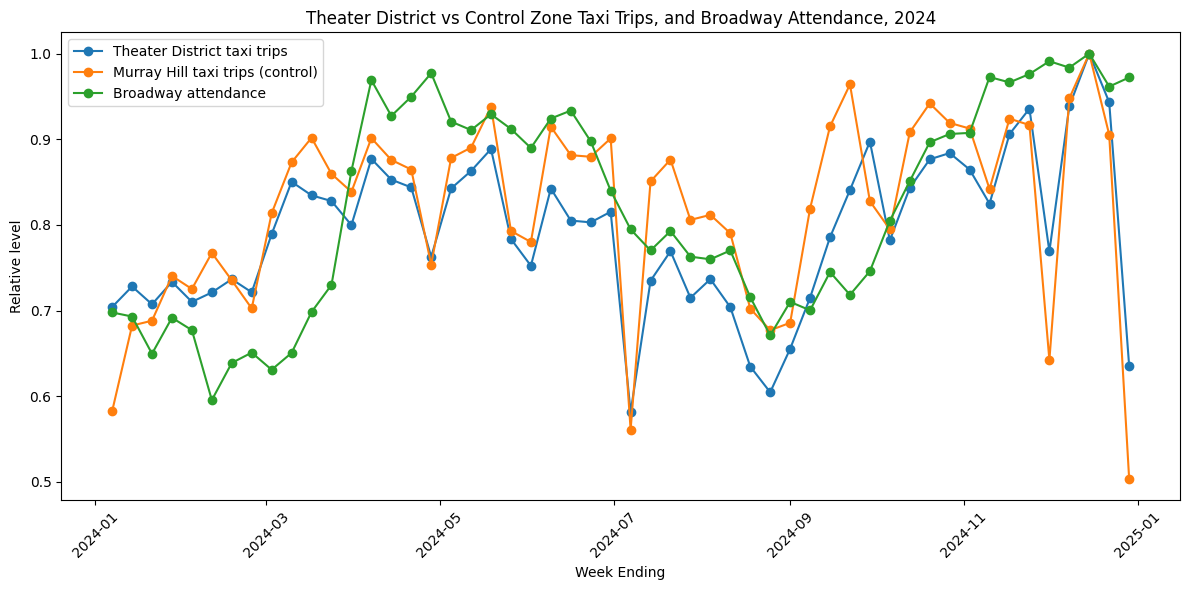

In [8]:
control_plot_data["trips_scaled"] = (
    control_plot_data["weekly_trips"] / control_plot_data["weekly_trips"].max()
)

plt.figure(figsize=(12, 6))
plt.plot(plot_data["week_ending"], plot_data["trips_scaled"],
         marker="o", label="Theater District taxi trips")
plt.plot(control_plot_data["week_ending"], control_plot_data["trips_scaled"],
         marker="o", label=f"{control_zone_name} taxi trips (control)")
plt.plot(plot_data["week_ending"], plot_data["attendance_scaled"],
         marker="o", label="Broadway attendance")
plt.xlabel("Week Ending")
plt.ylabel("Relative level")
plt.title("Theater District vs Control Zone Taxi Trips, and Broadway Attendance, 2024")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

**HVFHV (Uber/Lyft/Via/Juno) comparison.** This data was already filtered and shape-logged in the previous notebook but hasn't been used yet — bring it into the same weekly join so we can see whether rideshare demand near the Theater District tracks Broadway attendance the same way Yellow Taxi does, more strongly, or not at all.

In [9]:
fhvhv_pearson_r, fhvhv_pearson_p = stats.pearsonr(
    fhvhv_plot_data["weekly_trips"], fhvhv_plot_data["attendance"]
)
fhvhv_spearman_r, fhvhv_spearman_p = stats.spearmanr(
    fhvhv_plot_data["weekly_trips"], fhvhv_plot_data["attendance"]
)

print("HVFHV (Theater District) vs Broadway attendance")
print(f"  Pearson  r = {fhvhv_pearson_r:.4f}  (p = {fhvhv_pearson_p:.4g})")
print(f"  Spearman r = {fhvhv_spearman_r:.4f}  (p = {fhvhv_spearman_p:.4g})")

HVFHV (Theater District) vs Broadway attendance
  Pearson  r = 0.1873  (p = 0.1837)
  Spearman r = 0.2178  (p = 0.1209)


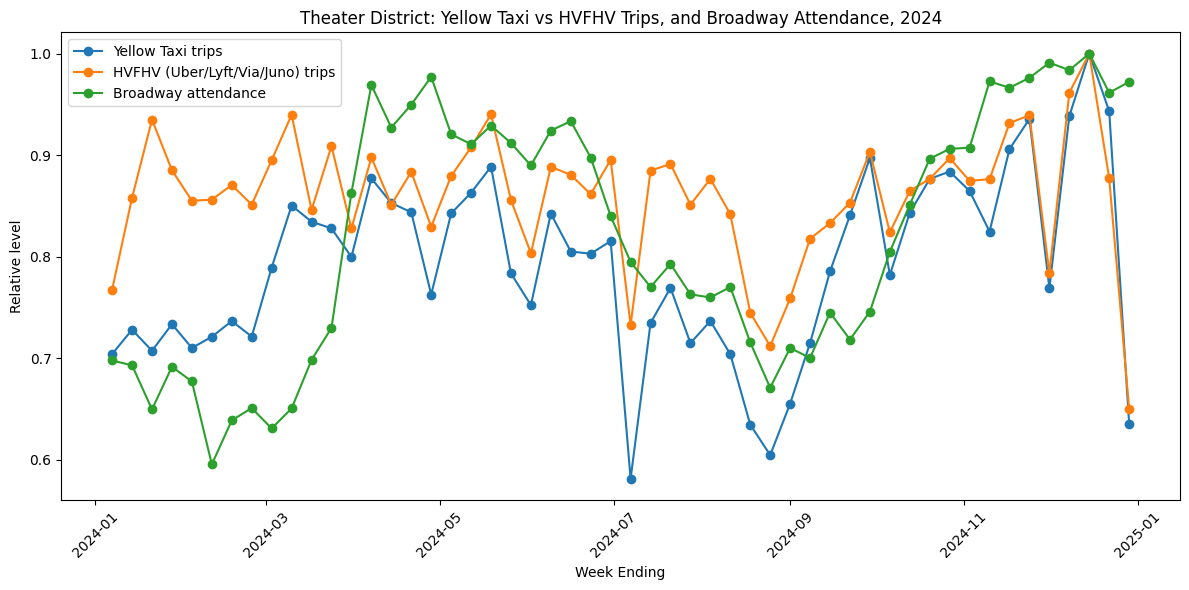

In [10]:
fhvhv_plot_data["trips_scaled"] = (
    fhvhv_plot_data["weekly_trips"] / fhvhv_plot_data["weekly_trips"].max()
)

plt.figure(figsize=(12, 6))
plt.plot(plot_data["week_ending"], plot_data["trips_scaled"],
         marker="o", label="Yellow Taxi trips")
plt.plot(fhvhv_plot_data["week_ending"], fhvhv_plot_data["trips_scaled"],
         marker="o", label="HVFHV (Uber/Lyft/Via/Juno) trips")
plt.plot(plot_data["week_ending"], plot_data["attendance_scaled"],
         marker="o", label="Broadway attendance")
plt.xlabel("Week Ending")
plt.ylabel("Relative level")
plt.title("Theater District: Yellow Taxi vs HVFHV Trips, and Broadway Attendance, 2024")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

**Summary of all correlations with Broadway attendance:**

In [11]:
print(f"  Yellow Taxi (Theater District)                : r = {pearson_r:.4f}  (p = {pearson_p:.4g})")
print(f"  Yellow Taxi ({control_zone_name}, control)".ljust(48) + f": r = {control_pearson_r:.4f}  (p = {control_pearson_p:.4g})")
print(f"  Yellow Taxi (de-trended, week-over-week change): r = {detrended_r:.4f}  (p = {detrended_p:.4g})")
print(f"  HVFHV (Theater District)                       : r = {fhvhv_pearson_r:.4f}  (p = {fhvhv_pearson_p:.4g})")

  Yellow Taxi (Theater District)                : r = 0.5652  (p = 1.27e-05)
  Yellow Taxi (Murray Hill, control)            : r = 0.3770  (p = 0.005874)
  Yellow Taxi (de-trended, week-over-week change): r = 0.0858  (p = 0.5496)
  HVFHV (Theater District)                       : r = 0.1873  (p = 0.1837)
